# 02. MLP (다층 퍼셉트론) & 역전파(Backpropagation)

## 🎯 이 노트북에서 배울 것
1. 은닉층을 쌓으면 **XOR 같은 선형 분리 불가 문제도 해결**할 수 있다
2. 역전파의 원리를 **numpy로 코드 한 줄 한 줄** 직접 구현하며 이해하기
3. 비선형 데이터(moons)에서의 결정 경계 시각화

## 📖 핵심 개념
- 구조: 입력층 → 은닉층(활성화 함수) → 출력층
- 순전파: `A1 = tanh(X·W1 + b1)`, `A2 = σ(A1·W2 + b2)`
- 역전파: 출력층의 오차를 **체인룰(연쇄 법칙)**로 거꾸로 전파해 각 가중치의 경사를 구함
  - `δ2 = (A2 − y) ⊙ σ'(Z2)`, `δ1 = (δ2·W2ᵀ) ⊙ tanh'(Z1)`
- 은닉층의 의미: 입력 공간을 **비선형으로 변환**해서 선형 분리가 가능하게 만드는 것


In [1]:
import numpy as np
import matplotlib.pyplot as plt

import matplotlib.font_manager as fm
# 한글 라벨이 깨지지 않도록,환경에 설치된 한글/CJK 폰트를 자동으로 찾아 설정
# (Windows: Malgun Gothic, macOS: AppleGothic, 리눅스: Noto Sans CJK KR 등)
_cjk_fonts = ["Malgun Gothic", "AppleGothic", "Noto Sans CJK KR", "Noto Sans KR",
              "NanumGothic", "WenQuanYi Zen Hei", "DejaVu Sans"]
_installed = {f.name for f in fm.fontManager.ttflist}
for _name in _cjk_fonts:
    if _name in _installed:
        plt.rcParams["font.family"] = _name
        break

np.random.seed(0)
plt.rcParams["figure.figsize"] = (7, 5)


## 1) XOR을 푸는 2-4-1 MLP (numpy로 역전파 직접 구현)

퍼셉트론이 실패했던 XOR를 은닉층 4개인 MLP가 해결합니다. 아래 코드에서 역전파 부분을특히주의 깊이 보세요.


In [2]:
# XOR 데이터 (출력은 0/1, 시그모이드 출력과 맞추기 위함)
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

class MLP:
    """은닉층 1개인 MLP (2-4-1), tanh 은닉층 + 시그모이드 출력, MSE 손실, 수동 역전파"""
    def __init__(self, n_in=2, n_hidden=4, n_out=1, lr=0.5, epochs=8000):
        rng = np.random.default_rng(0)
        # Xavier/He 초기화: 가중치를 '입력 차원의 제곱근'에 비례한 작은 값으로 시작해야
        # 활성화 함수가 포화(saturation)되지 않아 경사가 잘 흐르고 학습이 됨
        self.W1 = rng.normal(0, np.sqrt(2.0 / n_in), (n_in, n_hidden))
        self.b1 = np.zeros(n_hidden)
        self.W2 = rng.normal(0, np.sqrt(2.0 / n_hidden), (n_hidden, n_out))
        self.b2 = np.zeros(n_out)
        self.lr = lr
        self.epochs = epochs
        self.loss_ = []

    @staticmethod
    def sigmoid(z):
        return 1.0 / (1.0 + np.exp(-z))

    def forward(self, X):
        # ── 순전파 (forward) ──
        self.Z1 = X @ self.W1 + self.b1     # 은닉층 가중합
        self.A1 = np.tanh(self.Z1)          # 은닉층 활성화: tanh (0 중심이라 학습이 안정적)
        self.Z2 = self.A1 @ self.W2 + self.b2
        self.A2 = self.sigmoid(self.Z2)     # 출력층 활성화: 이진 분류이므로 시그모이드 (0~1 확률)
        return self.A2

    def fit(self, X, y):
        for epoch in range(self.epochs):
            out = self.forward(X)
            self.loss_.append(((out - y) ** 2).mean())   # MSE 손실 기록

            # ── 역전파 (backward): 출력층 → 은닉층 순서로 오차 전파 ──
            # 출력층 오차 δ2 = (A2 - y) ⊙ σ'(Z2)   (MSE + 시그모이드의 미분이 곱해짐)
            dZ2 = (out - y) * out * (1 - out)
            dW2 = self.A1.T @ dZ2               # W2의 경사 = 은닉층 출력 × 출력층 오차
            db2 = dZ2.sum(axis=0)
            dA1 = dZ2 @ self.W2.T               # 은닉층으로 전달되는 오차 (체인룰: W2를 곱함)
            dZ1 = dA1 * (1 - self.A1 ** 2)      # tanh의 미분: tanh'(z) = 1 - tanh²(z)
            dW1 = X.T @ dZ1
            db1 = dZ1.sum(axis=0)

            # ── 경사하강법 갱신: 오차를 줄이는 방향(-경사)으로 가중치 이동 ──
            self.W2 -= self.lr * dW2
            self.b2 -= self.lr * db2
            self.W1 -= self.lr * dW1
            self.b1 -= self.lr * db1
        return self

    def predict(self, X):
        return (self.forward(X) >= 0.5).astype(int)   # 시그모이드 출력이 0.5 이상이면 1


입력: [[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]
MLP 예측: [0 1 1 0]   정답: [0. 1. 1. 0.]
XOR 정확도: 1.0  ← 단층 퍼셉트론은 불가능했던 문제!


/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49552 (\N{HANGUL SYLLABLE SON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44257 (\N{HANGUL SYLLABLE GOG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr

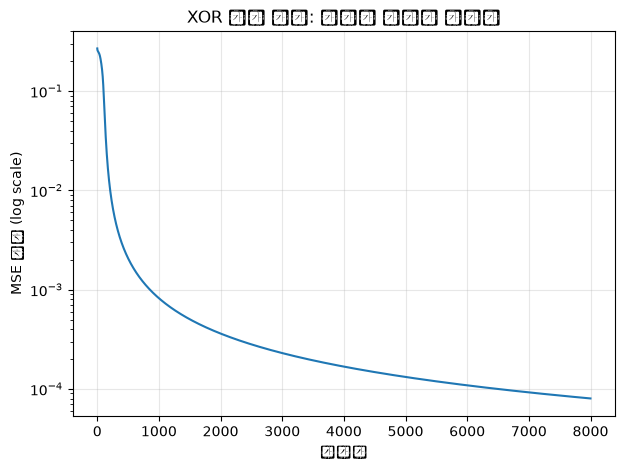

In [3]:
mlp = MLP(lr=0.5, epochs=8000)
mlp.fit(X, y)

print("입력:", X)
print("MLP 예측:", mlp.predict(X).ravel(), "  정답:", y.ravel())
print("XOR 정확도:", (mlp.predict(X) == y).mean(), " ← 단층 퍼셉트론은 불가능했던 문제!")

plt.plot(mlp.loss_)
plt.yscale("log")   # 손실이 수렴하는 모습을 보기 좋게 로그 스케일로
plt.xlabel("에포크"); plt.ylabel("MSE 손실 (log scale)")
plt.title("XOR 학습 곡선: 은닉층 덕분에 수렴함")
plt.grid(alpha=0.3); plt.show()


## 2) 비선형 데이터(moons)에서 MLP의 결정 경계

두 개의 초승달 모양 데이터는 직선으로 나눌 수 없습니다. 은닉층이 16개인 MLP가 **휘어진 결정 경계**를 만드는 것을 확인해보세요.


/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 45936 (\N{HANGUL SYLLABLE DE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 53552 (\N{HANGUL SYLLABLE TEO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51649 (\N{HANGUL SYLLABLE JIG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51004 (\N{HANGUL SYLLABLE EU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/loca

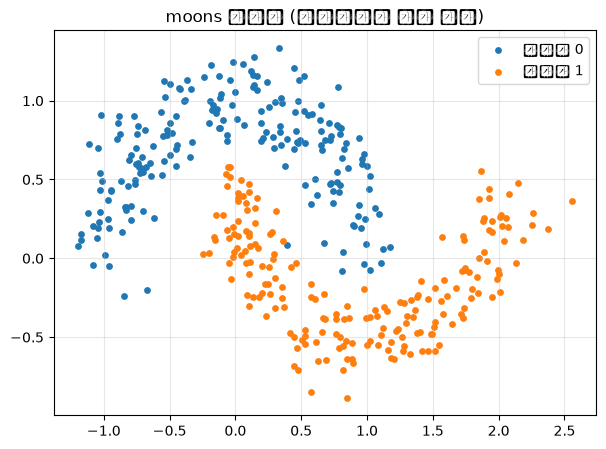

In [4]:
def make_moons(n=400, noise=0.15, seed=1):
    # sklearn 없이 numpy로 직접 만드는 moons 데이터셋
    rng = np.random.default_rng(seed)
    n1 = n // 2
    t = rng.uniform(0, np.pi, n1)
    X1 = np.column_stack([np.cos(t), np.sin(t)])          # 위쪽 반원
    t2 = rng.uniform(0, np.pi, n - n1)
    X2 = np.column_stack([1 - np.cos(t2), 0.5 - np.sin(t2)])  # 아래쪽 반원 (맞물린 형태)
    X = np.vstack([X1, X2]) + rng.normal(0, noise, (n, 2))    # 약간의 노이즈 추가
    y = np.array([0] * n1 + [1] * (n - n1))
    return X, y.reshape(-1, 1)

X, y = make_moons()
plt.scatter(X[y.ravel() == 0, 0], X[y.ravel() == 0, 1], s=15, label="클래스 0")
plt.scatter(X[y.ravel() == 1, 0], X[y.ravel() == 1, 1], s=15, label="클래스 1")
plt.legend(); plt.title("moons 데이터 (직선으로는 분리 불가)"); plt.grid(alpha=0.3); plt.show()


In [5]:
mlp2 = MLP(n_in=2, n_hidden=16, n_out=1, lr=0.1, epochs=3000)
mlp2.fit(X, y)
print("moons 정확도:", (mlp2.predict(X) == y).mean())
print("최종 손실:", mlp2.loss_[-1])


moons 정확도: 0.9975
최종 손실: 0.0011606694627980482


/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 47564 (\N{HANGUL SYLLABLE MAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 46304 (\N{HANGUL SYLLABLE DEUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54805 (\N{HANGUL SYLLABLE HYEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


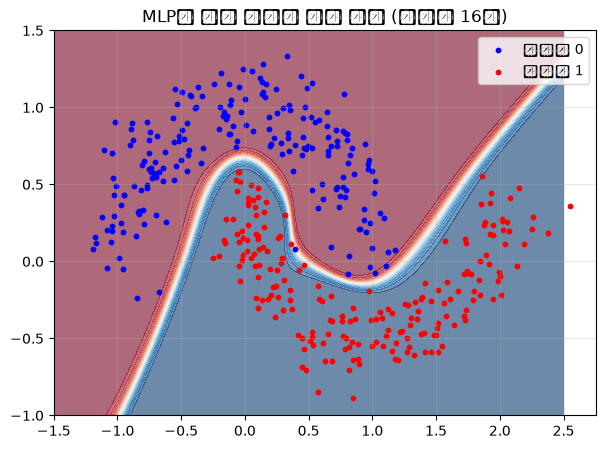

In [6]:
# 2D 전체 영역에 대해 모델 출력을 계산해 '결정 경계 heatmap' 그리기
xx, yy = np.meshgrid(np.linspace(-1.5, 2.5, 200), np.linspace(-1.0, 1.5, 200))
grid = np.column_stack([xx.ravel(), yy.ravel()])
zz = mlp2.forward(grid).reshape(xx.shape)

plt.contourf(xx, yy, zz, levels=20, cmap="RdBu", alpha=0.6)
plt.scatter(X[y.ravel() == 0, 0], X[y.ravel() == 0, 1], c="blue", s=10, label="클래스 0")
plt.scatter(X[y.ravel() == 1, 0], X[y.ravel() == 1, 1], c="red", s=10, label="클래스 1")
plt.legend(); plt.title("MLP가 만든 비선형 결정 경계 (은닉층 16개)")
plt.grid(alpha=0.3); plt.show()


## ✅ 정리

- **은닉층 + 비선형 활성화 함수**가 입력 공간을 뒤틀어서 선형 분리가 가능하게 만듦 → XOR 해결
- **역전파** = 체인룰로 출력층 오차를 거꾸로 전파해 모든 가중치의 경사를 효율적으로 계산하는 방법
- 주의: 은닉층이 깊어지면 경사가 소실(vanishing gradient)될 수 있음 → ReLU,잔차 연결(ResNet) 등으로 해결 (이후 과정)
- 다음: [$03$: 볼츠만 머신](./03_Boltzmann_Machine.ipynb) — 생성 모델의 고전, RBM을 numpy로 구현
